# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170325          # <-- your full roll number
NAME = "Vansh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170325   Name: Vansh   Fingerprint: 512DA46B   Tickets: 12

Ticket_ID                                                                                         Ticket_Text
      T01 I keep getting logged out of the VPN when connected to campus Wi-Fi. The same problem occurs again.
      T02                     I tried restarting the MATLAB after restarting the system. It worked yesterday.
      T03                                        The projector stopped responding. Is there another solution?
      T04                                                                       Why isn't the portal opening?
      T05                                                      Re-installing didn't help; log-in still fails!
      T06                                   I can't open the LMS after restarting the system. This is urgent.
      T07                       I cannot access the Wi-Fi when connected to campus Wi-Fi. Can you check this?
      T08                                  

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Your code
import string
import pandas as pd
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    for ch in token:
        if ch not in string.punctuation:
            return False
    return True

def process_ticket(text):
  sentences = sent_tokenize(text)
  tokens=[]
  for s in sentences:
    words = word_tokenize(s)
    for w in words:
      tokens.append(w.lower())
  punct = [t for t in tokens if is_punct(t)]
  stops = [t for t in tokens if t in STOP]
  final=[t for t in tokens if not is_punct(t) and t not in STOP]
  return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

data=[]

for i in range(len(df)):
  ticket_id=df.iloc[i]["Ticket_ID"]
  ticket_text=df.iloc[i]["Ticket_Text"]

  res = process_ticket(ticket_text)
  sentences = res["sentences"]
  tokens = res["tokens"]
  punct = res["punct"]
  stops = res["stops"]
  final = res["final"]

  data.append([ticket_id,sentences,tokens,punct,stops,len(set(tokens)),len(final)])

result=pd.DataFrame(
    data,
    columns=["Ticket_ID","Sentences","Tokens","Punctuation","Stopwords","Unique_Tokens","Final_Tokens"]
)

print(result)

total={
    "Ticket_ID":"Total",
    "Sentences":result["Sentences"].apply(len).sum(),
    "Tokens":result["Tokens"].apply(len).sum(),
    "Punctuation":result["Punctuation"].apply(len).sum(),
    "Stopwords":result["Stopwords"].apply(len).sum(),
    "Unique_Tokens":result["Unique_Tokens"].sum(),
    "Final_Tokens":result["Final_Tokens"].sum()
}

result.loc[len(result)]=total
print("\nTable with total")
print(result)

selected_ticket=FOCUS[0]

text=df[df["Ticket_ID"]==selected_ticket]["Ticket_Text"].values[0]

res = process_ticket(text)
sentences = res["sentences"]
tokens = res["tokens"]
punct = res["punct"]
stops = res["stops"]
final = res["final"]

print("\nSelected ticket:",selected_ticket)
print("Ticket text:",text)
print("Tokens:",tokens)
print("Punctuation:",punct)
print("Stopwords:",stops)
print("Final tokens:",final)

   Ticket_ID                                          Sentences  \
0        T01  [I keep getting logged out of the VPN when con...   
1        T02  [I tried restarting the MATLAB after restartin...   
2        T03  [The projector stopped responding., Is there a...   
3        T04                    [Why isn't the portal opening?]   
4        T05   [Re-installing didn't help; log-in still fails!]   
5        T06  [I can't open the LMS after restarting the sys...   
6        T07  [I cannot access the Wi-Fi when connected to c...   
7        T08                     [My roll no., is 1023-03-021.]   
8        T09  [The VPN keeps disconnecting., It worked yeste...   
9        T10  [I can't open the server during the lab., I do...   
10       T11  [The projector is running slowly., Please reso...   
11       T12           [Only 2 of 30 PCs boot after 3.5 hours.]   

                                               Tokens Punctuation  \
0   [i, keep, getting, logged, out, of, the, vpn, ...      

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
pattern_long_words = r"[a-zA-Z]{6,}"

pattern_numbers = r"\d+(?:\.\d+)*"

pattern_capitalized = r"[A-Z][a-zA-Z]*"

pattern_vowels = r"\b[aeiouAEIOU][a-zA-Z]*\b"

pattern_email = r"[a-zA-Z0-9.-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]+"

pattern_url = r"https?://[^\s;]+|www\.[a-zA-Z0-9.-]+\.[a-zA-Z]+"

pattern_phone = r"\+?\d[\d\s-]{8,14}\d"

def analyze_text(text, label=""):
    print(f"Analysis for {label}:")
    print("Original:", text)
    print("Words > 5 letters:", re.findall(pattern_long_words, text))
    print("Numbers:", re.findall(pattern_numbers, text))
    print("Capitalized words:", re.findall(pattern_capitalized, text))
    print("Vowel-starting words:", re.findall(pattern_vowels, text))

    subbed = re.sub(pattern_email, "<EMAIL>", text)
    subbed = re.sub(pattern_url, "<URL>", subbed)
    subbed = re.sub(pattern_phone, "<PHONE>", subbed)
    print("After substitutions:", subbed)

for idx, line in enumerate(TEST_LINES):
    analyze_text(line, f"TEST_LINE {idx+1}")

print("\n\n" + " ANALYSIS ON ALL DATASET TICKETS "+"\n")
for idx, row in df.iterrows():
    analyze_text(row["Ticket_Text"], f"Ticket {row['Ticket_ID']}")

Analysis for TEST_LINE 1:
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel-starting words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
After substitutions: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>/it.
Analysis for TEST_LINE 2:
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words > 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel-starting words: ['or', 'is']
After substitutions: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Analysis for TEST_LINE 3:
Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words > 5 letters: []
Number

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern1=r"https?://\S+|www\.\S+"
pattern2=r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
pattern3=r"\b\d{10}\b"
pattern4=r"\b\d+(?:\.\d+)*\b"
pattern5=r"[A-Za-z]+(?:[-'][A-Za-z]+)*"

my_pattern=pattern1 + "|" + pattern2 + "|" + pattern3 + "|" + pattern4 + "|" + pattern5

my_tokenizer=RegexpTokenizer(my_pattern)

for line in TEST_LINES:
    print("Text:",line)
    print("Custom Tokens:",my_tokenizer.tokenize(line))
    print("Word Tokens:",word_tokenize(line))
    print("/n")

for idx,row in df.iterrows():
    text=row["Ticket_Text"]
    print(f"Ticket {row['Ticket_ID']}:{text}")
    print("Custom Tokens:",my_tokenizer.tokenize(text))
    print("Word Tokens:",word_tokenize(text))
    print("/n")

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom Tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Word Tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
/n
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom Tokens: ['Call', '91', '98765', '43210', '91', '98765', '43210', 'or', '0175', '239', '3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
Word Tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
/n
Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom Tokens: ['The',

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
# Your code

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

all_final=[]
for idx,row in df.iterrows():
    res=process_ticket(row["Ticket_Text"])
    all_final.extend(res["final"])

unique_final=sorted(set(all_final))

porter=PorterStemmer()
lancaster=LancasterStemmer()
lemmatizer=WordNetLemmatizer()

suffix_options=["ing", "ed", "ly", "es", "s"]
chosen_suffix="ing"
best_count=0
best_words=[]

for suffix in suffix_options:
    words_with_suffix=[]

    for word in unique_final:
        if word.isalpha() and word.endswith(suffix) and len(word)>len(suffix)+2:
            words_with_suffix.append(word)

    if len(words_with_suffix)>best_count:
        best_count=len(words_with_suffix)
        chosen_suffix=suffix
        best_words=words_with_suffix

regexp_stemmer=RegexpStemmer(chosen_suffix + r"$")

tagged_words=pos_tag(unique_final)
rows=[]

for word,tag in tagged_words:
    if tag.startswith("J"):
        pos="a"
    elif tag.startswith("V"):
        pos="v"
    elif tag.startswith("N"):
        pos="n"
    elif tag.startswith("R"):
        pos="r"
    else:
        pos="n"

    porter_word=porter.stem(word)
    lancaster_word=lancaster.stem(word)
    regexp_word=regexp_stemmer.stem(word)
    lemma_word=lemmatizer.lemmatize(word, pos=pos)

    if len(set([porter_word, lancaster_word, regexp_word, lemma_word]))>1:
        row = {
            "Word":word,
            "POS":tag,
            "Porter":porter_word,
            "Lancaster":lancaster_word,
            "Regexp":regexp_word,
            "WordNet lemma":lemma_word
        }

        rows.append(row)

comparison=pd.DataFrame(rows)
display(comparison)

print("Regexp stemmer removes the suffix:",chosen_suffix)
print("Words in my dataset ending with this suffix:",best_words)
print("This suffix was selected because it appeared most often in the suitable words in my dataset.")

print("\nObservation:")
print("Stemming can shorten words too much. Lemmatization uses the word and its part of speech to find a base form.")

,Word,POS,Porter,Lancaster,Regexp,WordNet lemma
0,another,DT,anoth,anoth,another,another
1,campus,VB,campu,camp,campus,campus
2,changed,VBD,chang,chang,changed,change
3,connected,VBD,connect,connect,connected,connect
4,fails,NNS,fail,fail,fails,fails
5,getting,VBG,get,get,gett,get
6,hours,NNS,hour,hour,hours,hour
7,keeps,NNS,keep,keep,keeps,keep
8,lms,JJ,lm,lms,lms,lms
9,logged,VBD,log,log,logged,log


Regexp stemmer removes the suffix: ing
Words in my dataset ending with this suffix: ['disconnecting', 'getting', 'opening', 'responding', 'restarting', 'running']
This suffix was selected because it appeared most often in the suitable words in my dataset.

Observation:
Stemming can shorten words too much. Lemmatization uses the word and its part of speech to find a base form.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1: all tokens,145,80,0.551724
1,S2: without punctuation,123,76,0.617886
2,S3: final tokens,69,52,0.753623
3,S4: Porter stemmed,69,50,0.724638


Top 10 words in S1:
[('.', 17), ('the', 13), ('i', 6), ('is', 5), ("n't", 5), ('wi-fi', 3), ('restarting', 3), ('after', 3), ('it', 3), ('?', 3)]

Top 10 words in S3:
[("n't", 5), ('wi-fi', 3), ('restarting', 3), ('vpn', 2), ('connected', 2), ('campus', 2), ('system', 2), ('worked', 2), ('yesterday', 2), ('projector', 2)]


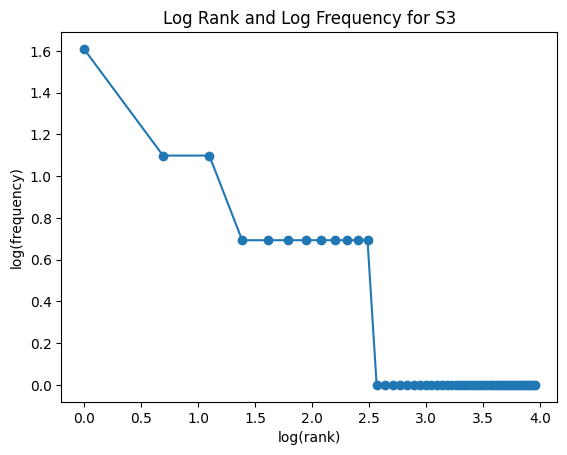


Top 5 bigrams in S1:
[(('.', 'the'), 4), (('.', 'i'), 4), (('restarting', 'the'), 3), (('the', 'vpn'), 2), (('when', 'connected'), 2)]

Top 5 bigrams in S3:
[(('connected', 'campus'), 2), (('campus', 'wi-fi'), 2), (('restarting', 'system'), 2), (('worked', 'yesterday'), 2), (('ca', "n't"), 2)]

Observation:
TTR means the number of unique tokens divided by the total number of tokens.
TTR can change because stopwords and punctuation are removed and stemming changes word forms.


In [9]:
# Your code
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from nltk.util import ngrams
import pandas as pd

processed={}
for idx,row in df.iterrows():
    processed[row["Ticket_ID"]]=process_ticket(row["Ticket_Text"])

S1=[]
S2=[]
S3=[]

for ticket_id in processed:
    result=processed[ticket_id]

    S1.extend(result["tokens"])
    S3.extend(result["final"])

    for token in result["tokens"]:
        if not is_punct(token):
            S2.append(token)

S4=[]

for token in S3:
    S4.append(porter.stem(token))

corpus_names=["S1: all tokens", "S2: without punctuation", "S3: final tokens", "S4: Porter stemmed"]
corpus_lists=[S1, S2, S3, S4]

rows=[]

for i in range(len(corpus_lists)):
    tokens=corpus_lists[i]
    total_tokens=len(tokens)
    unique_tokens=len(set(tokens))

    if total_tokens>0:
        ttr=unique_tokens/total_tokens
    else:
        ttr=0

    rows.append({
        "Corpus":corpus_names[i],
        "Total tokens":total_tokens,
        "Unique tokens":unique_tokens,
        "TTR":ttr
    })

stats = pd.DataFrame(rows)
display(stats)

print("Top 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

word_counts=Counter(S3)
ranked_words=word_counts.most_common()

ranks=[]
frequencies=[]

for i in range(len(ranked_words)):
    ranks.append(i+1)
    frequencies.append(ranked_words[i][1])

if len(ranks)>0:
    plt.plot(np.log(ranks), np.log(frequencies),marker="o")
    plt.xlabel("log(rank)")
    plt.ylabel("log(frequency)")
    plt.title("Log Rank and Log Frequency for S3")
    plt.show()

print("\nTop 5 bigrams in S1:")
print(Counter(ngrams(S1,2)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(ngrams(S3,2)).most_common(5))

print("\nObservation:")
print("TTR means the number of unique tokens divided by the total number of tokens.")
print("TTR can change because stopwords and punctuation are removed and stemming changes word forms.")

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*